In [2]:
import pandas as pd, sqlite3

df = pd.read_csv("data/online_retail_II.csv", parse_dates=["InvoiceDate"])
print("Raw rows:", len(df))

df = df.dropna(subset=["Customer ID"])
df["Invoice"] = df["Invoice"].astype(str)
df = df[~df["Invoice"].str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].drop_duplicates()
df["TotalPrice"] = df["Quantity"] * df["Price"]
df["CustomerID"] = df["Customer ID"].astype(int)
df["InvoiceDate"] = df["InvoiceDate"].dt.strftime("%Y-%m-%d %H:%M:%S")

print("Clean rows:", len(df))

Raw rows: 1067371
Clean rows: 779425


In [3]:
conn = sqlite3.connect("data/retail.db")
df.drop(columns=["Customer ID"]).to_sql("transactions", conn, if_exists="replace", index=False)
print("Saved to retail.db")

Saved to retail.db


In [4]:
query = """
SELECT
  CustomerID,
  CAST(julianday('2011-09-09') - julianday(MAX(InvoiceDate)) AS INT) AS recency_days,
  COUNT(DISTINCT Invoice)                                            AS frequency,
  ROUND(SUM(TotalPrice), 2)                                          AS monetary,
  ROUND(SUM(TotalPrice) / COUNT(DISTINCT Invoice), 2)                AS avg_order_value,
  CAST(julianday('2011-09-09') - julianday(MIN(InvoiceDate)) AS INT) AS tenure_days,
  COUNT(DISTINCT StockCode)                                          AS distinct_products
FROM transactions
WHERE InvoiceDate <= '2011-09-09 23:59:59'
GROUP BY CustomerID;
"""
features = pd.read_sql(query, conn)
print(features.shape)
features.describe()

(5281, 7)


,CustomerID,recency_days,frequency,monetary,avg_order_value,tenure_days,distinct_products
count,5281.000000,5281.000000,5281.000000,5281.000000,5281.000000,5281.000000,5281.000000
mean,15324.100170,205.824086,5.745692,2637.863283,369.292511,430.319068,74.356751
std,1712.323865,175.017502,11.464582,12225.544953,538.206192,180.514537,104.968606
min,12346.000000,0.000000,1.000000,2.900000,2.900000,0.000000,1.000000
25%,13850.000000,48.000000,1.000000,318.240000,174.670000,310.000000,18.000000
50%,15313.000000,162.000000,3.000000,783.580000,276.860000,472.000000,41.000000
75%,16807.000000,325.000000,6.000000,2078.540000,409.730000,585.000000,92.000000
max,18287.000000,646.000000,309.000000,456780.490000,14844.770000,646.000000,2182.000000


In [5]:
# Customers who bought during the next 90 days (10 Sep to 9 Dec 2011)
future_query = """
SELECT DISTINCT CustomerID
FROM transactions
WHERE InvoiceDate >  '2011-09-09 23:59:59'
  AND InvoiceDate <= '2011-12-09 23:59:59'
"""
returned = pd.read_sql(future_query, conn)

# churn = 1 if the customer did NOT come back, else 0
features["churn"] = (~features["CustomerID"].isin(returned["CustomerID"])).astype(int)

print(features["churn"].value_counts())
print("Churn rate:", round(features["churn"].mean() * 100, 1), "%")

churn
1    2989
0    2292
Name: count, dtype: int64
Churn rate: 56.6 %


In [6]:
features["recency_group"] = pd.qcut(features["recency_days"], 4,
                                    labels=["Very recent", "Recent", "Old", "Very old"])
print(features.groupby("recency_group", observed=True)["churn"].mean().round(2))

recency_group
Very recent    0.27
Recent         0.47
Old            0.68
Very old       0.85
Name: churn, dtype: float64


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Score each customer 1-5 on R, F, M (5 = best)
# rank(method="first") avoids errors, because many customers share frequency = 1
features["R"] = pd.qcut(features["recency_days"].rank(method="first"), 5, labels=[5,4,3,2,1]).astype(int)
features["F"] = pd.qcut(features["frequency"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
features["M"] = pd.qcut(features["monetary"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)

def label(r):
    if r.R >= 4 and r.F >= 4: return "Champions"
    if r.R >= 3 and r.F >= 3: return "Loyal"
    if r.R >= 4 and r.F <= 2: return "New / Promising"
    if r.R <= 2 and r.F >= 4: return "At Risk (valuable)"
    if r.R <= 2 and r.F >= 2: return "Slipping"
    return "Lost / Low value"

features["rfm_segment"] = features.apply(label, axis=1)

summary = features.groupby("rfm_segment").agg(
    customers=("CustomerID", "count"),
    churn_rate=("churn", "mean"),
    revenue=("monetary", "sum")).round(2)
summary["revenue_share_%"] = (summary["revenue"] / summary["revenue"].sum() * 100).round(1)
summary.sort_values("revenue", ascending=False)

,customers,churn_rate,revenue,revenue_share_%
rfm_segment,,,,
Champions,1388,0.23,9921953.70,71.2
Loyal,1004,0.50,1841727.09,13.2
At Risk (valuable),319,0.67,811860.29,5.8
Slipping,1096,0.78,733470.74,5.3
Lost / Low value,1093,0.82,426498.75,3.1
New / Promising,381,0.52,195045.43,1.4


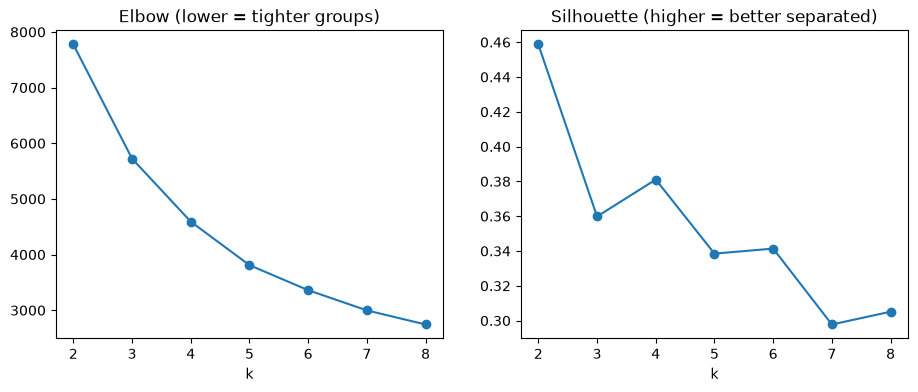

{2: np.float64(0.459), 3: np.float64(0.36), 4: np.float64(0.381), 5: np.float64(0.338), 6: np.float64(0.341), 7: np.float64(0.298), 8: np.float64(0.305)}


In [8]:
X = np.log1p(features[["recency_days", "frequency", "monetary"]])
X_scaled = StandardScaler().fit_transform(X)

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow (lower = tighter groups)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, marker="o");     ax[1].set_title("Silhouette (higher = better separated)"); ax[1].set_xlabel("k")
plt.show()
print(dict(zip(ks, np.round(sil, 3))))

In [9]:
K = 4   # starting guess; we'll confirm after seeing your plots
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X_scaled)
features["cluster"] = km.labels_

profile = features.groupby("cluster").agg(
    customers=("CustomerID", "count"),
    avg_recency=("recency_days", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean"),
    churn_rate=("churn", "mean"),
    total_revenue=("monetary", "sum")).round(1)
profile["revenue_share_%"] = (profile["total_revenue"] / profile["total_revenue"].sum() * 100).round(1)
profile

,customers,avg_recency,avg_frequency,avg_monetary,churn_rate,total_revenue,revenue_share_%
cluster,,,,,,,
0,1662,189.4,5.2,2030.0,0.5,3373881.7,24.2
1,866,28.1,19.7,10836.1,0.2,9384066.3,67.4
2,596,27.0,2.6,717.9,0.4,427894.6,3.1
3,2157,339.2,1.4,345.3,0.8,744713.4,5.3


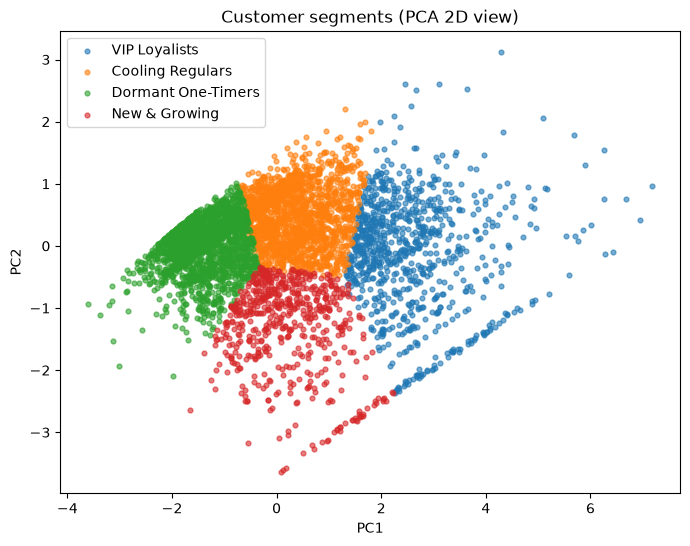

Variance explained: [0.76 0.19]


In [10]:
from sklearn.decomposition import PCA

names = {1: "VIP Loyalists", 0: "Cooling Regulars", 2: "New & Growing", 3: "Dormant One-Timers"}
features["segment_name"] = features["cluster"].map(names)

# Squash 3 features into 2 axes so we can draw the groups on a flat plot
pca = PCA(n_components=2, random_state=42)
pts = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
for name in features["segment_name"].unique():
    m = (features["segment_name"] == name).values
    plt.scatter(pts[m, 0], pts[m, 1], s=12, alpha=0.6, label=name)
plt.legend(); plt.title("Customer segments (PCA 2D view)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()
print("Variance explained:", pca.explained_variance_ratio_.round(2))

features.to_csv("data/features_segments.csv", index=False)

In [11]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

feat_cols = ["recency_days", "frequency", "monetary",
             "avg_order_value", "tenure_days", "distinct_products"]
X = features[feat_cols]
y = features["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8,
                             eval_metric="logloss", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    model.fit(X_train, y_train)
    test_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    rows.append((name, round(cv_auc, 3), round(test_auc, 3)))

pd.DataFrame(rows, columns=["model", "cv_auc", "test_auc"])

,model,cv_auc,test_auc
0,Logistic Regression,0.788,0.801
1,Random Forest,0.793,0.806
2,XGBoost,0.793,0.809


              precision    recall  f1-score   support

      stayed       0.75      0.63      0.69       459
     churned       0.75      0.84      0.79       598

    accuracy                           0.75      1057
   macro avg       0.75      0.74      0.74      1057
weighted avg       0.75      0.75      0.75      1057



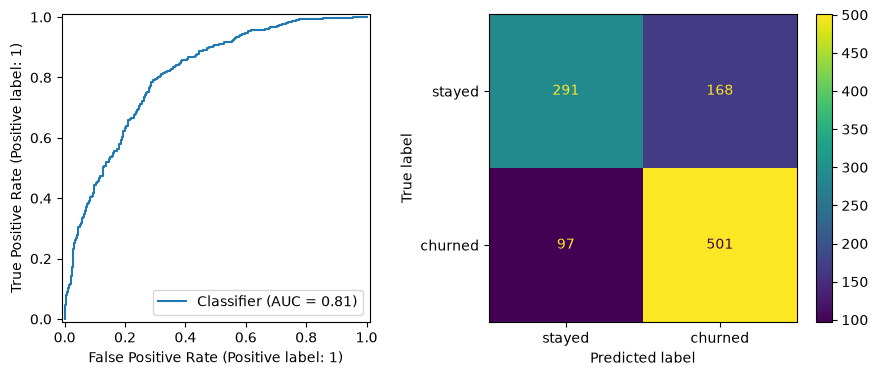

In [12]:
from sklearn.metrics import classification_report, RocCurveDisplay, ConfusionMatrixDisplay

best = models["XGBoost"]
proba = best.predict_proba(X_test)[:, 1]     # churn probability for each test customer
pred = (proba >= 0.5).astype(int)            # say "churn" if probability is 50% or more

print(classification_report(y_test, pred, target_names=["stayed", "churned"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[0])
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["stayed", "churned"], ax=ax[1])
plt.show()

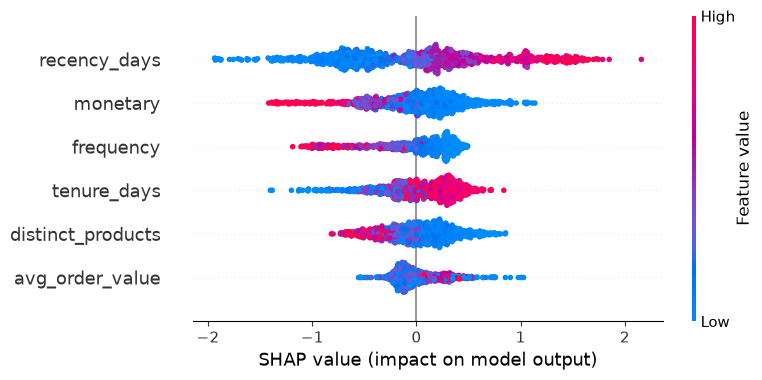

In [13]:
import shap
explainer = shap.TreeExplainer(best)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

In [14]:
from sklearn.model_selection import cross_val_predict

# 1. Churn probability for EVERY customer, scored fairly (out-of-fold)
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    eval_metric="logloss", random_state=42)
features["churn_prob"] = cross_val_predict(xgb, X, y, cv=cv, method="predict_proba")[:, 1]

# 2. Value if the customer stays: their usual spend per 90 days
features["value_90d"] = features["monetary"] / features["tenure_days"].clip(lower=90) * 90

# 3. Revenue at risk = chance of leaving x what they'd spend
features["revenue_at_risk"] = features["churn_prob"] * features["value_90d"]

print("Total revenue at risk (next 90 days): £", round(features["revenue_at_risk"].sum()))

# How concentrated is the risk?
ranked = features.sort_values("revenue_at_risk", ascending=False).reset_index(drop=True)
n20 = int(len(ranked) * 0.2)
share = ranked.loc[:n20 - 1, "revenue_at_risk"].sum() / ranked["revenue_at_risk"].sum()
print(f"Top 20% of customers hold {share:.0%} of the revenue at risk")

# By segment
seg = features.groupby("segment_name").agg(
    customers=("CustomerID", "count"),
    avg_churn_prob=("churn_prob", "mean"),
    revenue_at_risk=("revenue_at_risk", "sum")).round(2)
seg["share_%"] = (seg["revenue_at_risk"] / seg["revenue_at_risk"].sum() * 100).round(1)
display(seg.sort_values("revenue_at_risk", ascending=False))

# Ready-to-use call list
priority = ranked[["CustomerID", "segment_name", "churn_prob", "value_90d", "revenue_at_risk"]].round(2)
priority.head(50).to_csv("data/priority_customers.csv", index=False)
priority.head(10)

Total revenue at risk (next 90 days): £ 745029
Top 20% of customers hold 56% of the revenue at risk


,customers,avg_churn_prob,revenue_at_risk,share_%
segment_name,,,,
Cooling Regulars,1662,0.52,344687.07,46.3
Dormant One-Timers,2157,0.80,157513.41,21.1
VIP Loyalists,866,0.15,152058.83,20.4
New & Growing,596,0.44,90769.55,12.2


,CustomerID,segment_name,churn_prob,value_90d,revenue_at_risk
0,15098,Cooling Regulars,0.69,39916.50,27523.87
1,15749,Cooling Regulars,0.78,16700.36,13050.52
2,16754,VIP Loyalists,0.71,10737.72,7637.41
3,12346,VIP Loyalists,0.40,11026.98,4371.95
4,17850,VIP Loyalists,0.56,7178.81,3993.74
5,12482,VIP Loyalists,0.93,3800.76,3548.05
6,13902,Cooling Regulars,0.68,4855.34,3279.55
7,13093,VIP Loyalists,0.39,7578.51,2919.24
8,12454,Cooling Regulars,0.76,3597.66,2739.28
9,12590,Cooling Regulars,0.37,7460.36,2725.17


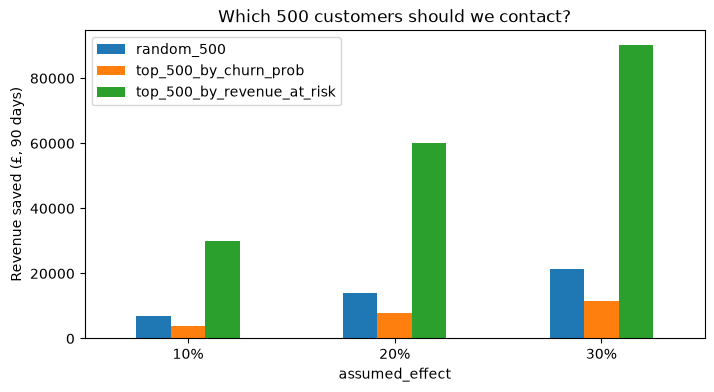

,assumed_effect,random_500,top_500_by_churn_prob,top_500_by_revenue_at_risk,net_gain_best_£
0,10%,7041.0,3857.0,30057.0,27557.0
1,20%,14043.0,7713.0,60114.0,57614.0
2,30%,21383.0,11570.0,90171.0,87671.0


In [15]:
N = 500                         # how many customers the team can contact
COST = 5                        # assumed cost per contact, in £
EFFECTS = [0.10, 0.20, 0.30]    # assumed: the offer cuts churn probability by 10/20/30%

rng = np.random.default_rng(42)

def saved(idx, effect):
    # money saved = effect x revenue that was at risk among the contacted customers
    return effect * features.loc[idx, "revenue_at_risk"].sum()

rows = []
for effect in EFFECTS:
    random_avg = np.mean([saved(rng.choice(features.index, N, replace=False), effect)
                          for _ in range(500)])
    by_prob = saved(features.nlargest(N, "churn_prob").index, effect)
    by_rar  = saved(features.nlargest(N, "revenue_at_risk").index, effect)
    rows.append((f"{effect:.0%}", random_avg, by_prob, by_rar))

sim = pd.DataFrame(rows, columns=["assumed_effect", "random_500",
                                  "top_500_by_churn_prob", "top_500_by_revenue_at_risk"]).round(0)
sim["net_gain_best_£"] = sim["top_500_by_revenue_at_risk"] - N * COST

sim.set_index("assumed_effect")[["random_500", "top_500_by_churn_prob",
                                 "top_500_by_revenue_at_risk"]].plot(kind="bar", figsize=(8, 4))
plt.ylabel("Revenue saved (£, 90 days)")
plt.title("Which 500 customers should we contact?")
plt.xticks(rotation=0); plt.show()
sim